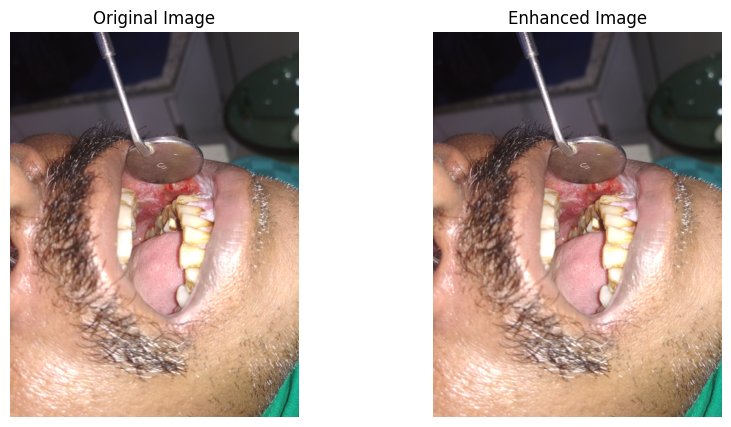

In [3]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

def linear_enhancement(image_array, min_val=0, max_val=255):
    """
    Apply linear enhancement to an RGB image array using min and max values.
    
    Parameters:
        image_array (numpy.ndarray): Input RGB image array.
        min_val (float): Minimum value for linear enhancement (default 0).
        max_val (float): Maximum value for linear enhancement (default 255).
    
    Returns:
        numpy.ndarray: Enhanced image array.
    """
    # Ensure image array is in float32 format
    image_array = image_array.astype(np.float32)
    
    # Compute the scaling factor and shift
    min_img_val = image_array.min()
    max_img_val = image_array.max()
    
    # Scale and shift to the new range [min_val, max_val]
    scale = (max_val - min_val) / (max_img_val - min_img_val)
    shift = min_val - min_img_val * scale
    
    enhanced_image_array = image_array * scale + shift
    
    # Clip values to be in the range [min_val, max_val]
    enhanced_image_array = np.clip(enhanced_image_array, min_val, max_val)
    
    # Convert back to uint8 format
    enhanced_image_array = enhanced_image_array.astype(np.uint8)
    
    return enhanced_image_array

# Load the image
image_path = 'test_practice/test_practice/b6abfb73-IMG_20200830_111000.jpg'
image = Image.open(image_path).convert('RGB')
image_array = np.array(image)

# Apply linear enhancement
min_val = 0   # Minimum value in the output image
max_val = 255 # Maximum value in the output image
enhanced_image_array = linear_enhancement(image_array, min_val, max_val)

# Convert array back to PIL Image and save
enhanced_image = Image.fromarray(enhanced_image_array)
enhanced_image.save('enhanced_image.jpg')

# Plot both images
plt.figure(figsize=(10, 5))

# Original Image
plt.subplot(1, 2, 1)
plt.title("Original Image")
plt.imshow(image)
plt.axis('off')

# Enhanced Image
plt.subplot(1, 2, 2)
plt.title("Enhanced Image")
plt.imshow(enhanced_image)
plt.axis('off')

plt.show()


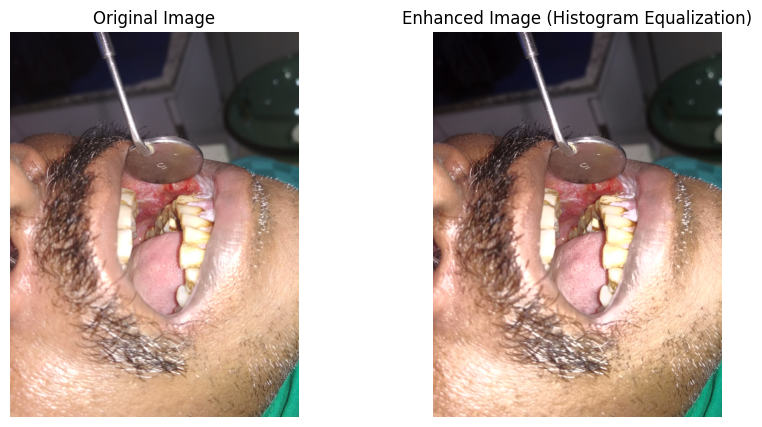

In [4]:
import numpy as np
from PIL import Image
import cv2
import matplotlib.pyplot as plt

def histogram_equalization(image_array):
    """
    Apply histogram equalization to an RGB image array.
    
    Parameters:
        image_array (numpy.ndarray): Input RGB image array.
    
    Returns:
        numpy.ndarray: Enhanced image array.
    """
    # Convert RGB to YUV
    yuv_image = cv2.cvtColor(image_array, cv2.COLOR_RGB2YUV)
    
    # Equalize the Y channel (luminance)
    yuv_image[:,:,0] = cv2.equalizeHist(yuv_image[:,:,0])
    
    # Convert back to RGB
    enhanced_image_array = cv2.cvtColor(yuv_image, cv2.COLOR_YUV2RGB)
    
    return enhanced_image_array

# Load the image
image_path = 'test_practice/test_practice/b6abfb73-IMG_20200830_111000.jpg'
image = Image.open(image_path).convert('RGB')
image_array = np.array(image)

# Apply histogram equalization
enhanced_image_array = histogram_equalization(image_array)

# Convert array back to PIL Image and save
enhanced_image = Image.fromarray(enhanced_image_array)
enhanced_image.save('enhanced_image_histogram_equalized.jpg')

# Plot both images
plt.figure(figsize=(10, 5))

# Original Image
plt.subplot(1, 2, 1)
plt.title("Original Image")
plt.imshow(image)
plt.axis('off')

# Enhanced Image
plt.subplot(1, 2, 2)
plt.title("Enhanced Image (Histogram Equalization)")
plt.imshow(enhanced_image)
plt.axis('off')

plt.show()


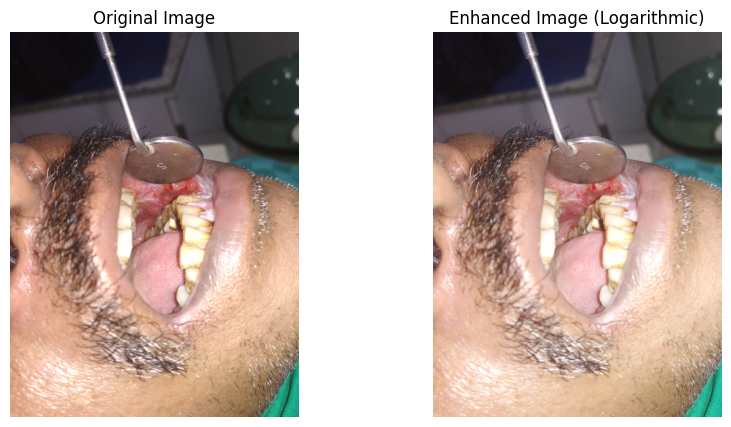

In [7]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

def logarithmic_enhancement(image_array, c=1.0):
    """
    Apply logarithmic enhancement to an RGB image array.
    
    Parameters:
        image_array (numpy.ndarray): Input RGB image array.
        c (float): Scaling constant to control the effect of the logarithmic transformation.
    
    Returns:
        numpy.ndarray: Enhanced image array.
    """
    # Convert image array to float32 for precision in calculations
    image_array = image_array.astype(np.float32)
    
    # Normalize pixel values to the range [0, 1]
    image_array_normalized = image_array / 255.0
    
    # Apply logarithmic transformation
    enhanced_image_array = c * np.log1p(image_array_normalized)  # log1p is log(1 + x) to avoid log(0)
    
    # Normalize back to [0, 255]
    enhanced_image_array = (enhanced_image_array / enhanced_image_array.max()) * 255.0
    
    # Convert back to uint8 format
    enhanced_image_array = np.clip(enhanced_image_array, 0, 255).astype(np.uint8)
    
    return enhanced_image_array

# Load the image
image_path = 'test_practice/test_practice/b6abfb73-IMG_20200830_111000.jpg'
image = Image.open(image_path).convert('RGB')
image_array = np.array(image)

# Apply logarithmic enhancement
c = 1.0  # Scaling constant
enhanced_image_array = logarithmic_enhancement(image_array, c)

# Convert array back to PIL Image and save
enhanced_image = Image.fromarray(enhanced_image_array)
enhanced_image.save('enhanced_image_logarithmic.jpg')

# Plot both images
plt.figure(figsize=(10, 5))

# Original Image
plt.subplot(1, 2, 1)
plt.title("Original Image")
plt.imshow(image)
plt.axis('off')

# Enhanced Image
plt.subplot(1, 2, 2)
plt.title("Enhanced Image (Logarithmic)")
plt.imshow(enhanced_image)
plt.axis('off')

plt.show()


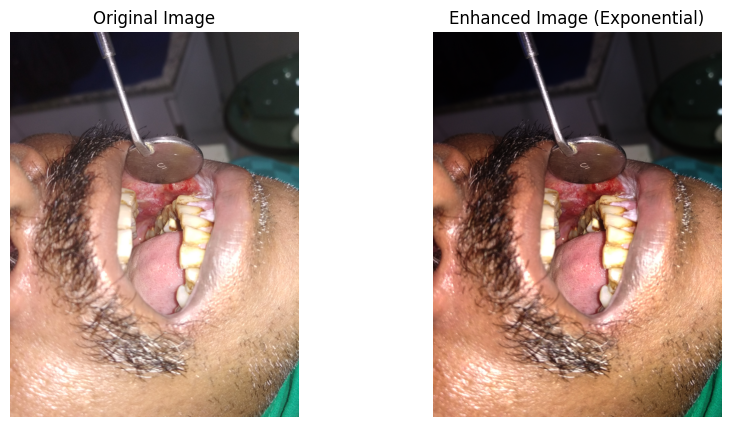

In [11]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

def exponential_enhancement(image_array, gamma=1.0):
    """
    Apply exponential enhancement to an RGB image array.
    
    Parameters:
        image_array (numpy.ndarray): Input RGB image array.
        gamma (float): Exponential factor to control the enhancement effect.
    
    Returns:
        numpy.ndarray: Enhanced image array.
    """
    # Convert image array to float32 for precision in calculations
    image_array = image_array.astype(np.float32)
    
    # Normalize pixel values to the range [0, 1]
    image_array_normalized = image_array / 255.0
    
    # Apply exponential transformation
    enhanced_image_array = np.power(image_array_normalized, gamma)
    
    # Normalize back to [0, 255]
    enhanced_image_array = (enhanced_image_array / enhanced_image_array.max()) * 255.0
    
    # Convert back to uint8 format
    enhanced_image_array = np.clip(enhanced_image_array, 0, 255).astype(np.uint8)
    
    return enhanced_image_array

# Load the image
image_path = 'test_practice/test_practice/b6abfb73-IMG_20200830_111000.jpg'
image = Image.open(image_path).convert('RGB')
image_array = np.array(image)

# Apply exponential enhancement
gamma = 1.5  # Exponential factor
enhanced_image_array = exponential_enhancement(image_array, gamma)

# Convert array back to PIL Image and save
enhanced_image = Image.fromarray(enhanced_image_array)
enhanced_image.save('enhanced_image_exponential.jpg')

# Plot both images
plt.figure(figsize=(10, 5))

# Original Image
plt.subplot(1, 2, 1)
plt.title("Original Image")
plt.imshow(image)
plt.axis('off')

# Enhanced Image
plt.subplot(1, 2, 2)
plt.title("Enhanced Image (Exponential)")
plt.imshow(enhanced_image)
plt.axis('off')

plt.show()


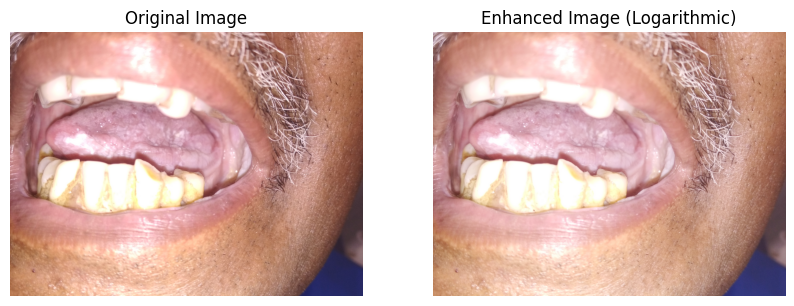

In [8]:

import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

def logarithmic_enhancement(image_array, c=1.0):
    """
    Apply logarithmic enhancement to an RGB image array.
    
    Parameters:
        image_array (numpy.ndarray): Input RGB image array.
        c (float): Scaling constant to control the effect of the logarithmic transformation.
    
    Returns:
        numpy.ndarray: Enhanced image array.
    """
    # Convert image array to float32 for precision in calculations
    image_array = image_array.astype(np.float32)
    
    # Normalize pixel values to the range [0, 1]
    image_array_normalized = image_array / 255.0
    
    # Apply logarithmic transformation
    enhanced_image_array = c * np.log1p(image_array_normalized)  # log1p is log(1 + x) to avoid log(0)
    
    # Normalize back to [0, 255]
    enhanced_image_array = (enhanced_image_array / enhanced_image_array.max()) * 255.0
    
    # Convert back to uint8 format
    enhanced_image_array = np.clip(enhanced_image_array, 0, 255).astype(np.uint8)
    
    return enhanced_image_array

# Load the image
image_path = 'test_practice/test_practice/a498304f-IMG_20200228_102021.jpg'
image = Image.open(image_path).convert('RGB')
image_array = np.array(image)

# Apply logarithmic enhancement
c = 1.0  # Scaling constant
enhanced_image_array = logarithmic_enhancement(image_array, c)

# Convert array back to PIL Image and save
enhanced_image = Image.fromarray(enhanced_image_array)
enhanced_image.save('enhanced_image_logarithmic.jpg')

# Plot both images
plt.figure(figsize=(10, 5))

# Original Image
plt.subplot(1, 2, 1)
plt.title("Original Image")
plt.imshow(image)
plt.axis('off')

# Enhanced Image
plt.subplot(1, 2, 2)
plt.title("Enhanced Image (Logarithmic)")
plt.imshow(enhanced_image)
plt.axis('off')

plt.show()


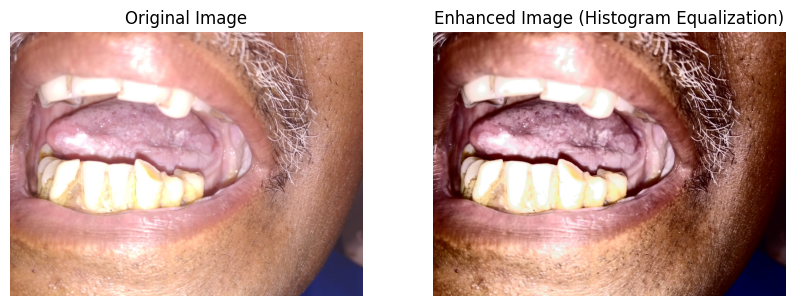

In [9]:
import numpy as np
import cv2
from PIL import Image
import matplotlib.pyplot as plt

def histogram_equalization(image_array):
    """
    Apply histogram equalization to an RGB image array.
    
    Parameters:
        image_array (numpy.ndarray): Input RGB image array.
    
    Returns:
        numpy.ndarray: Enhanced image array.
    """
    # Convert RGB to YUV
    yuv_image = cv2.cvtColor(image_array, cv2.COLOR_RGB2YUV)
    
    # Equalize the Y channel (luminance)
    yuv_image[:,:,0] = cv2.equalizeHist(yuv_image[:,:,0])
    
    # Convert back to RGB
    enhanced_image_array = cv2.cvtColor(yuv_image, cv2.COLOR_YUV2RGB)
    
    return enhanced_image_array

# Load the image
image_path = 'test_practice/test_practice/a498304f-IMG_20200228_102021.jpg'
image = Image.open(image_path).convert('RGB')
image_array = np.array(image)

# Apply histogram equalization
enhanced_image_array = histogram_equalization(image_array)

# Convert array back to PIL Image and save
enhanced_image = Image.fromarray(enhanced_image_array)
enhanced_image.save('enhanced_image_histogram_equalized.jpg')

# Plot both images
plt.figure(figsize=(10, 5))

# Original Image
plt.subplot(1, 2, 1)
plt.title("Original Image")
plt.imshow(image)
plt.axis('off')

# Enhanced Image
plt.subplot(1, 2, 2)
plt.title("Enhanced Image (Histogram Equalization)")
plt.imshow(enhanced_image)
plt.axis('off')

plt.show()


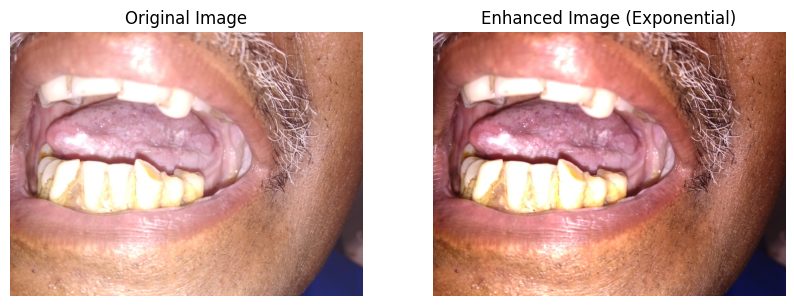

In [13]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

def exponential_enhancement(image_array, gamma=1.0):
    """
    Apply exponential enhancement to an RGB image array.
    
    Parameters:
        image_array (numpy.ndarray): Input RGB image array.
        gamma (float): Exponential factor to control the enhancement effect.
    
    Returns:
        numpy.ndarray: Enhanced image array.
    """
    # Convert image array to float32 for precision in calculations
    image_array = image_array.astype(np.float32)
    
    # Normalize pixel values to the range [0, 1]
    image_array_normalized = image_array / 255.0
    
    # Apply exponential transformation
    enhanced_image_array = np.power(image_array_normalized, gamma)
    
    # Normalize back to [0, 255]
    enhanced_image_array = (enhanced_image_array / enhanced_image_array.max()) * 255.0
    
    # Convert back to uint8 format
    enhanced_image_array = np.clip(enhanced_image_array, 0, 255).astype(np.uint8)
    
    return enhanced_image_array

# Load the image
image_path = 'test_practice/test_practice/a498304f-IMG_20200228_102021.jpg'
image = Image.open(image_path).convert('RGB')
image_array = np.array(image)

# Apply exponential enhancement
gamma = 1.5  # Exponential factor
enhanced_image_array = exponential_enhancement(image_array, gamma)

# Convert array back to PIL Image and save
enhanced_image = Image.fromarray(enhanced_image_array)
enhanced_image.save('enhanced_image_exponential.jpg')

# Plot both images
plt.figure(figsize=(10, 5))

# Original Image
plt.subplot(1, 2, 1)
plt.title("Original Image")
plt.imshow(image)
plt.axis('off')

# Enhanced Image
plt.subplot(1, 2, 2)
plt.title("Enhanced Image (Exponential)")
plt.imshow(enhanced_image)
plt.axis('off')

plt.show()


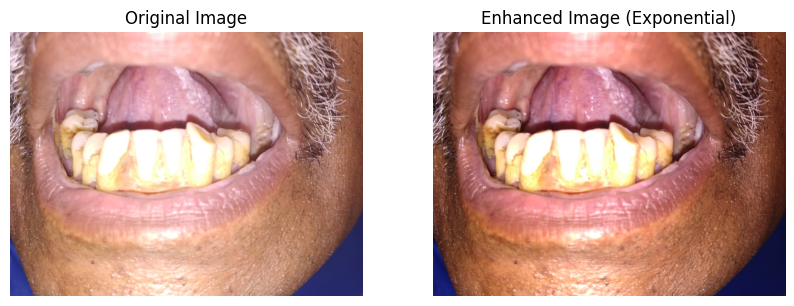

In [14]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

def exponential_enhancement(image_array, gamma=1.0):
    """
    Apply exponential enhancement to an RGB image array.
    
    Parameters:
        image_array (numpy.ndarray): Input RGB image array.
        gamma (float): Exponential factor to control the enhancement effect.
    
    Returns:
        numpy.ndarray: Enhanced image array.
    """
    # Convert image array to float32 for precision in calculations
    image_array = image_array.astype(np.float32)
    
    # Normalize pixel values to the range [0, 1]
    image_array_normalized = image_array / 255.0
    
    # Apply exponential transformation
    enhanced_image_array = np.power(image_array_normalized, gamma)
    
    # Normalize back to [0, 255]
    enhanced_image_array = (enhanced_image_array / enhanced_image_array.max()) * 255.0
    
    # Convert back to uint8 format
    enhanced_image_array = np.clip(enhanced_image_array, 0, 255).astype(np.uint8)
    
    return enhanced_image_array

# Load the image
image_path = 'test_practice/test_practice/a7786aa1-IMG_20200228_102048.jpg'
image = Image.open(image_path).convert('RGB')
image_array = np.array(image)

# Apply exponential enhancement
gamma = 1.5  # Exponential factor
enhanced_image_array = exponential_enhancement(image_array, gamma)

# Convert array back to PIL Image and save
enhanced_image = Image.fromarray(enhanced_image_array)
enhanced_image.save('enhanced_image_exponential.jpg')

# Plot both images
plt.figure(figsize=(10, 5))

# Original Image
plt.subplot(1, 2, 1)
plt.title("Original Image")
plt.imshow(image)
plt.axis('off')

# Enhanced Image
plt.subplot(1, 2, 2)
plt.title("Enhanced Image (Exponential)")
plt.imshow(enhanced_image)
plt.axis('off')

plt.show()


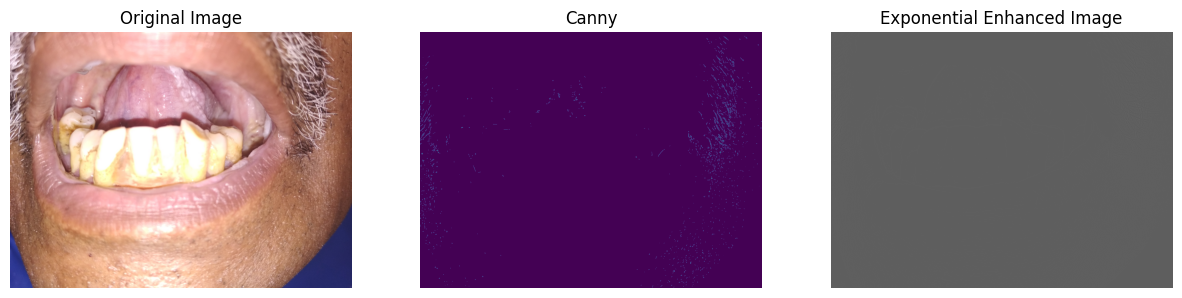

In [32]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import cv2

def laplacian_filter(image_array, scale=1.0):
    """
    Apply a more sensitive Laplacian filter to an RGB image array to enhance edges.
    
    Parameters:
        image_array (numpy.ndarray): Input RGB image array.
        scale (float): Scaling factor to increase the sensitivity of the Laplacian filter.
    
    Returns:
        numpy.ndarray: Enhanced image array with increased edge sensitivity.
    """
    # Convert to grayscale for Laplacian filtering
    gray_image = cv2.cvtColor(image_array, cv2.COLOR_RGB2GRAY)
    
    # Apply Laplacian filter
    ddepth = cv2.CV_64F
    kernel_size = 3
    laplacian_image = cv2.Laplacian(gray_image, ddepth=ddepth, ksize=kernel_size)
    
    # Scale the Laplacian result to enhance sensitivity
    laplacian_image = laplacian_image * scale
    
    # Normalize Laplacian image to [0, 255]
    laplacian_image = cv2.normalize(laplacian_image, None, 0, 255, cv2.NORM_MINMAX)
    
    # Convert to uint8 format
    laplacian_image = np.clip(laplacian_image, 0, 255).astype(np.uint8)
    
    # Convert back to RGB (3 channels)
    laplacian_image_rgb = cv2.cvtColor(laplacian_image, cv2.COLOR_GRAY2RGB)
    
    return laplacian_image_rgb

def exponential_enhancement(image_array, gamma=1.0):
    """
    Apply exponential enhancement to an RGB image array.
    
    Parameters:
        image_array (numpy.ndarray): Input RGB image array.
        gamma (float): Exponential factor to control the enhancement effect.
    
    Returns:
        numpy.ndarray: Enhanced image array.
    """
    # Convert image array to float32 for precision in calculations
    image_array = image_array.astype(np.float32)
    
    # Normalize pixel values to the range [0, 1]
    image_array_normalized = image_array / 255.0
    
    # Apply exponential transformation
    enhanced_image_array = np.power(image_array_normalized, gamma)
    
    # Normalize back to [0, 255]
    enhanced_image_array = (enhanced_image_array / enhanced_image_array.max()) * 255.0
    
    # Convert back to uint8 format
    enhanced_image_array = np.clip(enhanced_image_array, 0, 255).astype(np.uint8)
    
    return enhanced_image_array

# Load the image
image_path = 'test_practice/test_practice/a7786aa1-IMG_20200228_102048.jpg'
image = Image.open(image_path).convert('RGB')
image_array = np.array(image)
edges = cv2.Canny(image_array,200,300)
# Apply sensitive Laplacian filter
scale = 2.0  # Sensitivity scaling factor
laplacian_filtered_array = laplacian_filter(image_array, scale)

# Apply exponential enhancement
gamma = 1.5  # Exponential factor
exponential_enhanced_array = exponential_enhancement(laplacian_filtered_array, gamma)

# Convert arrays back to PIL Image
laplacian_filtered_image = Image.fromarray(laplacian_filtered_array)
exponential_enhanced_image = Image.fromarray(exponential_enhanced_array)

# Save enhanced images
laplacian_filtered_image.save('laplacian_filtered_image_sensitive.jpg')
exponential_enhanced_image.save('exponential_enhanced_image.jpg')

# Plot all three images
plt.figure(figsize=(15, 5))

# Original Image
plt.subplot(1, 3, 1)
plt.title("Original Image")
plt.imshow(image)
plt.axis('off')

# Sensitive Laplacian Filtered Image
plt.subplot(1, 3, 2)
plt.title("Canny")
plt.imshow(edges)
plt.axis('off')

# Exponential Enhanced Image
plt.subplot(1, 3, 3)
plt.title("Exponential Enhanced Image")
plt.imshow(exponential_enhanced_image)
plt.axis('off')

plt.show()


UnidentifiedImageError: cannot identify image file 'C:\\Users\\Public\\Projects\\DH307\\test_practice\\test_practice\\0101ffe9-20221217_210108.txt'

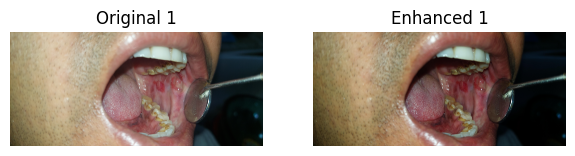

In [39]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import os

def exponential_enhancement(image_array, gamma=1.0):
    """
    Apply exponential enhancement to an RGB image array.
    
    Parameters:
        image_array (numpy.ndarray): Input RGB image array.
        gamma (float): Exponential factor to control the enhancement effect.
    
    Returns:
        numpy.ndarray: Enhanced image array.
    """
    # Convert image array to float32 for precision in calculations
    image_array = image_array.astype(np.float32)
    
    # Normalize pixel values to the range [0, 1]
    image_array_normalized = image_array / 255.0
    
    # Apply exponential transformation
    enhanced_image_array = np.power(image_array_normalized, gamma)
    
    # Normalize back to [0, 255]
    enhanced_image_array = (enhanced_image_array / enhanced_image_array.max()) * 255.0
    
    # Convert back to uint8 format
    enhanced_image_array = np.clip(enhanced_image_array, 0, 255).astype(np.uint8)
    
    return enhanced_image_array

# Input and output folder paths
input_folder = 'test_practice/test_practice'
output_folder = 'enhanced_images'

# Create output folder if it does not exist
os.makedirs(output_folder, exist_ok=True)

# List all files in the input folder
files = [f for f in os.listdir(input_folder) if os.path.isfile(os.path.join(input_folder, f))]

# Apply enhancement to each image and save to the output folder
for file in files:
    if(file.endswith('jpg')):
        image_path = os.path.join(input_folder, file)
        image = Image.open(image_path).convert('RGB')
        image_array = np.array(image)
        
        # Apply exponential enhancement
        gamma = 1.5  # Exponential factor
        enhanced_image_array = exponential_enhancement(image_array, gamma)
        
        # Convert array back to PIL Image and save
        enhanced_image = Image.fromarray(enhanced_image_array)
        enhanced_image.save(os.path.join(output_folder, file))

# Plot a few examples of original and enhanced images
example_files = files[:3]  # Take first 3 files for example

plt.figure(figsize=(15, 10))

for i, file in enumerate(example_files):
    # Original Image
    image_path = os.path.join(input_folder, file)
    image = Image.open(image_path).convert('RGB')
    
    # Enhanced Image
    enhanced_image_path = os.path.join(output_folder, file)
    enhanced_image = Image.open(enhanced_image_path).convert('RGB')
    
    # Plot Original Image
    plt.subplot(len(example_files), 4, i*4 + 1)
    plt.title(f"Original {i+1}")
    plt.imshow(image)
    plt.axis('off')
    
    # Plot Enhanced Image
    plt.subplot(len(example_files), 4, i*4 + 2)
    plt.title(f"Enhanced {i+1}")
    plt.imshow(enhanced_image)
    plt.axis('off')

plt.tight_layout()
plt.show()


In [ ]:
train_masks = [] 
for directory_path in glob.glob("labelled_images"):
    for mask_path in glob.glob(os.path.join(directory_path, "*jpg")):
        
        mask = cv2.imread(mask_path, 0)     
        mask = cv2.resize(mask, (SIZE_Y, SIZE_X), interpolation = cv2.INTER_NEAREST)  #Otherwise ground truth changes due to interpolation
        train_masks.append(mask)
        
#Convert list to array for machine learning processing          
train_masks = np.array(train_masks)
print(train_masks.shape)


In [35]:
import glob
import os
input_folder = 'test_practice/test_practice'
output_folder = 'enhanced_images'
for directory_path in glob.glob(input_folder):
    for image_path in glob.glob(os.path.join(directory_path, "*jpg")):
        print(image_path)
        break

test_practice/test_practice\0101ffe9-20221217_210108.jpg


In [1]:
#!/bin/python3

import math
import os
import random
import re
import sys



#
# Complete the 'getLongestMatch' function below.
#
# The function is expected to return an INTEGER.
# The function accepts following parameters:
#  1. STRING text
#  2. STRING regex
#

def getLongestMatch(text, regex):
    # Write your code here
    index = 0
    for i in range(len(regex)):
        if regex[i] == '*':
            index = i
            break
    left = regex[:index]
    right = regex[index+1:]
    
    p1 = 0
    p2 = index-1
    
    while p2!=len(text)-1:
        if text[p1:p2+1]==left:
            break
        else:
            p1+=1
            p2+=1
    # print(text[p1:p2+1])
   
    p3 = len(text)-1 - index
    p4 = len(text) - 1
    
    while p3!=p2:
        if text[p3:p4+1]==right:
            break
        else:
            p4-=1
            p3-=1
    print(text[p3:p4+1])
    if p3==p2:
        return -1
    else:
        return p4 - p1 + 1
            
    
    
    
         
    
    

        

if __name__ == '__main__':
    fptr = open(os.environ['OUTPUT_PATH'], 'w')

    text = input()

    regex = input()

    result = getLongestMatch(text, regex)

    fptr.write(str(result) + '\n')

    fptr.close()


KeyError: 'OUTPUT_PATH'